In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

# dataset 
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

y_train = y_train.flatten()
y_test = y_test.flatten()

NUM_CLASSES = 10
IMG_SIZE = 96
BATCH_SIZE = 64
EPOCHS = 5

# small subset for training and testing
x_train = x_train[:10000]
y_train = y_train[:10000]

x_test = x_test[:2000]
y_test = y_test[:2000]


def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = preprocess_input(image)
    return image, label


train_ds = tf.data.Dataset.from_tensor_slices(
    (x_train, y_train)
)

train_ds = (
    train_ds
    .shuffle(10000)
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (x_test, y_test)
)

test_ds = (
    test_ds
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 683s 4us/step


In [4]:
# load pretrained VGG16 
base_model_A = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# freeze all convolutional layers
base_model_A.trainable = False


inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = base_model_A(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model_A = Model(inputs, outputs)


# compile
model_A.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_A.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,642 (56.39 MB)

 Trainable params: 66,954 (261.54 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [5]:
trainable_A = np.sum([
    np.prod(v.shape)
    for v in model_A.trainable_weights
])

print("Experiment A Trainable Parameters:", trainable_A)

Experiment A Trainable Parameters: 66954


In [6]:
start_time = time.time()

history_A = model_A.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=test_ds
)

time_A = time.time() - start_time


# evaluate
loss_A, accuracy_A = model_A.evaluate(
    test_ds,
    verbose=0
)

print("\nExperiment A")
print("--------------------------")
print("Trainable Parameters:", trainable_A)
print(f"Training Time: {time_A:.2f} seconds")
print(f"Test Accuracy: {accuracy_A:.4f}")

Epoch 1/5


/Users/supriiyaaa/UCMO/Fall 2026/Neural Network/Home_Assignment_3/env/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


157/157 ━━━━━━━━━━━━━━━━━━━━ 178s 1s/step - accuracy: 0.5577 - loss: 1.9821 - val_accuracy: 0.7050 - val_loss: 0.8725
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 207s 1s/step - accuracy: 0.7208 - loss: 0.8516 - val_accuracy: 0.7515 - val_loss: 0.7481
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 223s 1s/step - accuracy: 0.7738 - loss: 0.6699 - val_accuracy: 0.7465 - val_loss: 0.7083
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 225s 1s/step - accuracy: 0.8113 - loss: 0.5385 - val_accuracy: 0.7615 - val_loss: 0.6764
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 241s 2s/step - accuracy: 0.8351 - loss: 0.4720 - val_accuracy: 0.7725 - val_loss: 0.6485

Experiment A
--------------------------
Trainable Parameters: 66954
Training Time: 1073.83 seconds
Test Accuracy: 0.7725


In [7]:
base_model_B = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# freeze everything first
base_model_B.trainable = True

# only block5 will remain trainable
for layer in base_model_B.layers:
    if layer.name.startswith("block5"):
        layer.trainable = True
    else:
        layer.trainable = False


# build classifier
inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3)
)

x = base_model_B(inputs)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model_B = Model(inputs, outputs)

In [8]:
model_B.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_B.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,642 (56.39 MB)

 Trainable params: 7,146,378 (27.26 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [9]:
trainable_B = np.sum([
    np.prod(v.shape)
    for v in model_B.trainable_weights
])

print("Experiment B Trainable Parameters:", trainable_B)

Experiment B Trainable Parameters: 7146378


In [10]:
start_time = time.time()

history_B = model_B.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=test_ds
)

time_B = time.time() - start_time


# evaluate
loss_B, accuracy_B = model_B.evaluate(
    test_ds,
    verbose=0
)

print("\nExperiment B")
print("--------------------------")
print("Trainable Parameters:", trainable_B)
print(f"Training Time: {time_B:.2f} seconds")
print(f"Test Accuracy: {accuracy_B:.4f}")

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 265s 2s/step - accuracy: 0.1736 - loss: 3.2160 - val_accuracy: 0.3110 - val_loss: 1.9517
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 256s 2s/step - accuracy: 0.3874 - loss: 1.7706 - val_accuracy: 0.5465 - val_loss: 1.3523
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 445s 3s/step - accuracy: 0.5634 - loss: 1.3084 - val_accuracy: 0.6425 - val_loss: 1.0782
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 256s 2s/step - accuracy: 0.6650 - loss: 1.0174 - val_accuracy: 0.6960 - val_loss: 0.9135
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 260s 2s/step - accuracy: 0.7301 - loss: 0.8132 - val_accuracy: 0.7255 - val_loss: 0.8198

Experiment B
--------------------------
Trainable Parameters: 7146378
Training Time: 1482.03 seconds
Test Accuracy: 0.7255


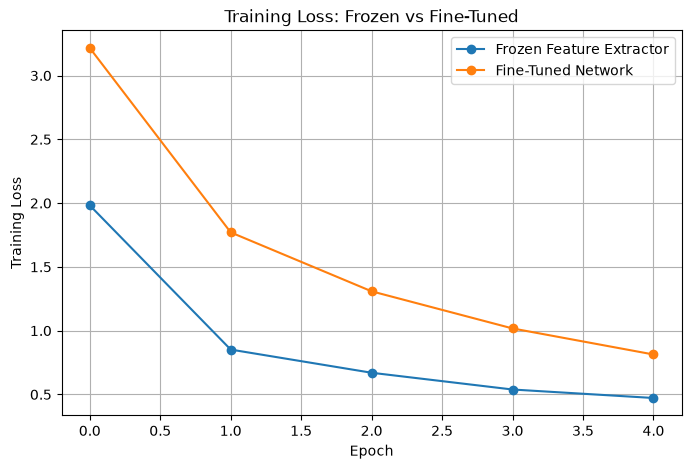

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_A.history["loss"],
    marker="o",
    label="Frozen Feature Extractor"
)

plt.plot(
    history_B.history["loss"],
    marker="o",
    label="Fine-Tuned Network"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss: Frozen vs Fine-Tuned")
plt.legend()
plt.grid()

plt.show()

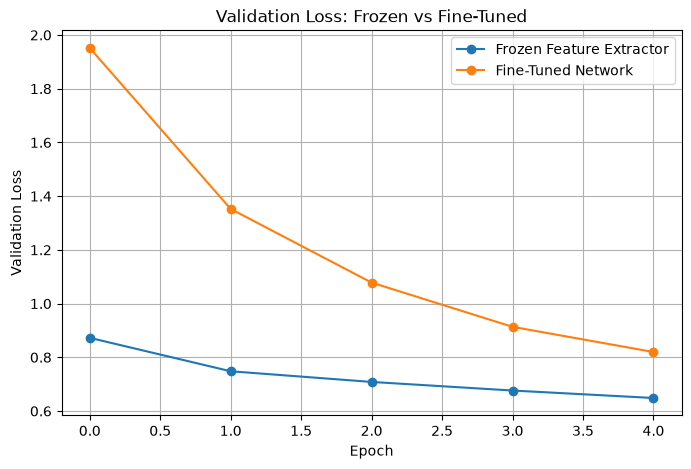

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_A.history["val_loss"],
    marker="o",
    label="Frozen Feature Extractor"
)

plt.plot(
    history_B.history["val_loss"],
    marker="o",
    label="Fine-Tuned Network"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss: Frozen vs Fine-Tuned")
plt.legend()
plt.grid()

plt.show()

In [13]:
print("\nComparison")
print("=" * 80)

print(
    f"{'Method':<28}"
    f"{'Trainable Params':<20}"
    f"{'Time (sec)':<15}"
    f"{'Accuracy':<12}"
)

print("-" * 80)

print(
    f"{'Frozen Feature Extractor':<28}"
    f"{trainable_A:<20}"
    f"{time_A:<15.2f}"
    f"{accuracy_A:<12.4f}"
)

print(
    f"{'Fine-Tuned Network':<28}"
    f"{trainable_B:<20}"
    f"{time_B:<15.2f}"
    f"{accuracy_B:<12.4f}"
)


Comparison
Method                      Trainable Params    Time (sec)     Accuracy    
--------------------------------------------------------------------------------
Frozen Feature Extractor    66954               1073.83        0.7725      
Fine-Tuned Network          7146378             1482.03        0.7255      


The frozen feature extractor had significantly fewer trainable parameters because all pretrained VGG16 convolutional layers were kept fixed. As a result, only the newly added classification layers were updated during training. This generally made the frozen model faster to train and required less computation. In the fine-tuning experiment, the final convolutional block was unfrozen, which greatly increased the number of trainable parameters. Fine-tuning allows high-level pretrained features to adapt specifically to the CIFAR-10 images and can therefore improve classification performance. However, updating additional convolutional layers requires more computation, resulting in a longer training time. Fine-tuning can also increase the risk of overfitting when the new dataset is small, which is why a small learning rate was used.